# 🌊 Tutorial: Port Wave Agitation Surrogate Modeling
### *Real-Time Operational Forecasting using Fourier Neural Operators & High-Fidelity Emulators*

**Authors**: Luis Zamorano (luiszamorano@inh.cl) & Yarko Niño (ynino@ing.uchile.cl)  
**Paper Reference**: *Manuscript submitted for publication*  

---

## Overview / Descripción General

This tutorial demonstrates the end-to-end workflow to implement and deploy AI-driven wave surrogates in a commercial port, using the **Port of San Antonio (Chile)** as the benchmark case study:

1. **Domain & Bathymetry**: Loading computational depth grids, generating water/land masks, and configuring control stations.
2. **Hindcast & MDA Selection**: Applying the Maximum Dissimilarity Algorithm (MDA) to sample optimal space-filling sea states.
3. **Tensor Construction**: Assembling 4-channel input tensors `[Hm0, FreqPeak, ThetaPeak, Depth]` and normalization.
4. **Neural Operator Inference**: Loading the pre-trained compact FNO model (`k=45, d=32`) to predict 2D wave fields in milliseconds.
5. **Operational Safeguards**: Automated **Convex Hull / Training Envelope Screening** to detect when sea states operate in safe interpolation vs hazardous extrapolation.
6. **Exporting to ParaView (VTK)**: Saving 2D fields for interactive 3D rendering.
7. **Generalization**: How to adapt this workflow to a new port domain.

### Step 0: Environment Setup & Library Import
We import `portsurrogate`, which provides high-level modular tools for coastal wave surrogates.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch

# Add package directory to path
nb_dir = os.getcwd()
pkg_dir = os.path.dirname(nb_dir)
if pkg_dir not in sys.path:
    sys.path.insert(0, pkg_dir)

import portsurrogate
from portsurrogate import (
    load_config,
    PortBathymetry,
    WaveDatasetBuilder,
    FNO2d,
    CustomNormalizer,
    check_training_envelope,
    plot_bathymetry,
    plot_spatial_comparison,
    export_field_to_vtk,
)

print(f"portsurrogate version: {portsurrogate.__version__}")
print(f"PyTorch available: {torch.__version__} (CUDA: {torch.cuda.is_available()})")

/home/model2/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


portsurrogate version: 1.0.0
PyTorch available: 2.7.1+cpu (CUDA: False)


### Step 1: Load Configuration for Port of San Antonio
All parameters (grid dimensions, crop slices, wavemaker convention, and control sites) are declaratively defined in `san_antonio.yaml`.

In [2]:
config_path = os.path.join(pkg_dir, "configs", "san_antonio.yaml")
cfg = load_config(config_path)

print(f"Port: {cfg.name} ({cfg.country})")
print(f"Full Grid: {cfg.grid.n_rows} x {cfg.grid.n_cols} cells (dx={cfg.grid.dx}m, dy={cfg.grid.dy}m)")
print(f"Surrogate Crop: {cfg.grid.crop.height} x {cfg.grid.crop.width} cells")
print("Control Sites:")
for k, site in cfg.control_sites.items():
    r_crop, c_crop = cfg.get_crop_site_coords(k)
    print(f"  - Site {k} ({site.name}): Full={site.coords_full}, Crop=({r_crop}, {c_crop}), Depth={site.depth_m}m")

Port: San Antonio (Chile)
Full Grid: 425 x 380 cells (dx=5.0m, dy=5.0m)
Surrogate Crop: 360 x 360 cells
Control Sites:
  - Site A (Site A (Outer fairway / intermediate)): Full=(93, 220), Crop=(60, 200), Depth=12.5m
  - Site B (Site B (Approach channel)): Full=(163, 204), Crop=(130, 184), Depth=11.2m
  - Site C (Site C (Harbor entrance - exposed)): Full=(176, 261), Crop=(143, 241), Depth=9.8m
  - Site D (Site D (Breakwater head - diffraction zone)): Full=(92, 282), Crop=(59, 262), Depth=8.5m
  - Site E (Site E (Inner sheltered basin / berthing)): Full=(215, 310), Crop=(182, 290), Depth=7.2m


### Step 2: Bathymetry & Computational Domain
We load the smoothed bathymetry (`Mod3`), generate the water mask (`depth > 0`), and plot the port domain with control stations.
Notice that `origin='lower'` is enforced so the breakwater appears at the South and the submarine canyon at the North.

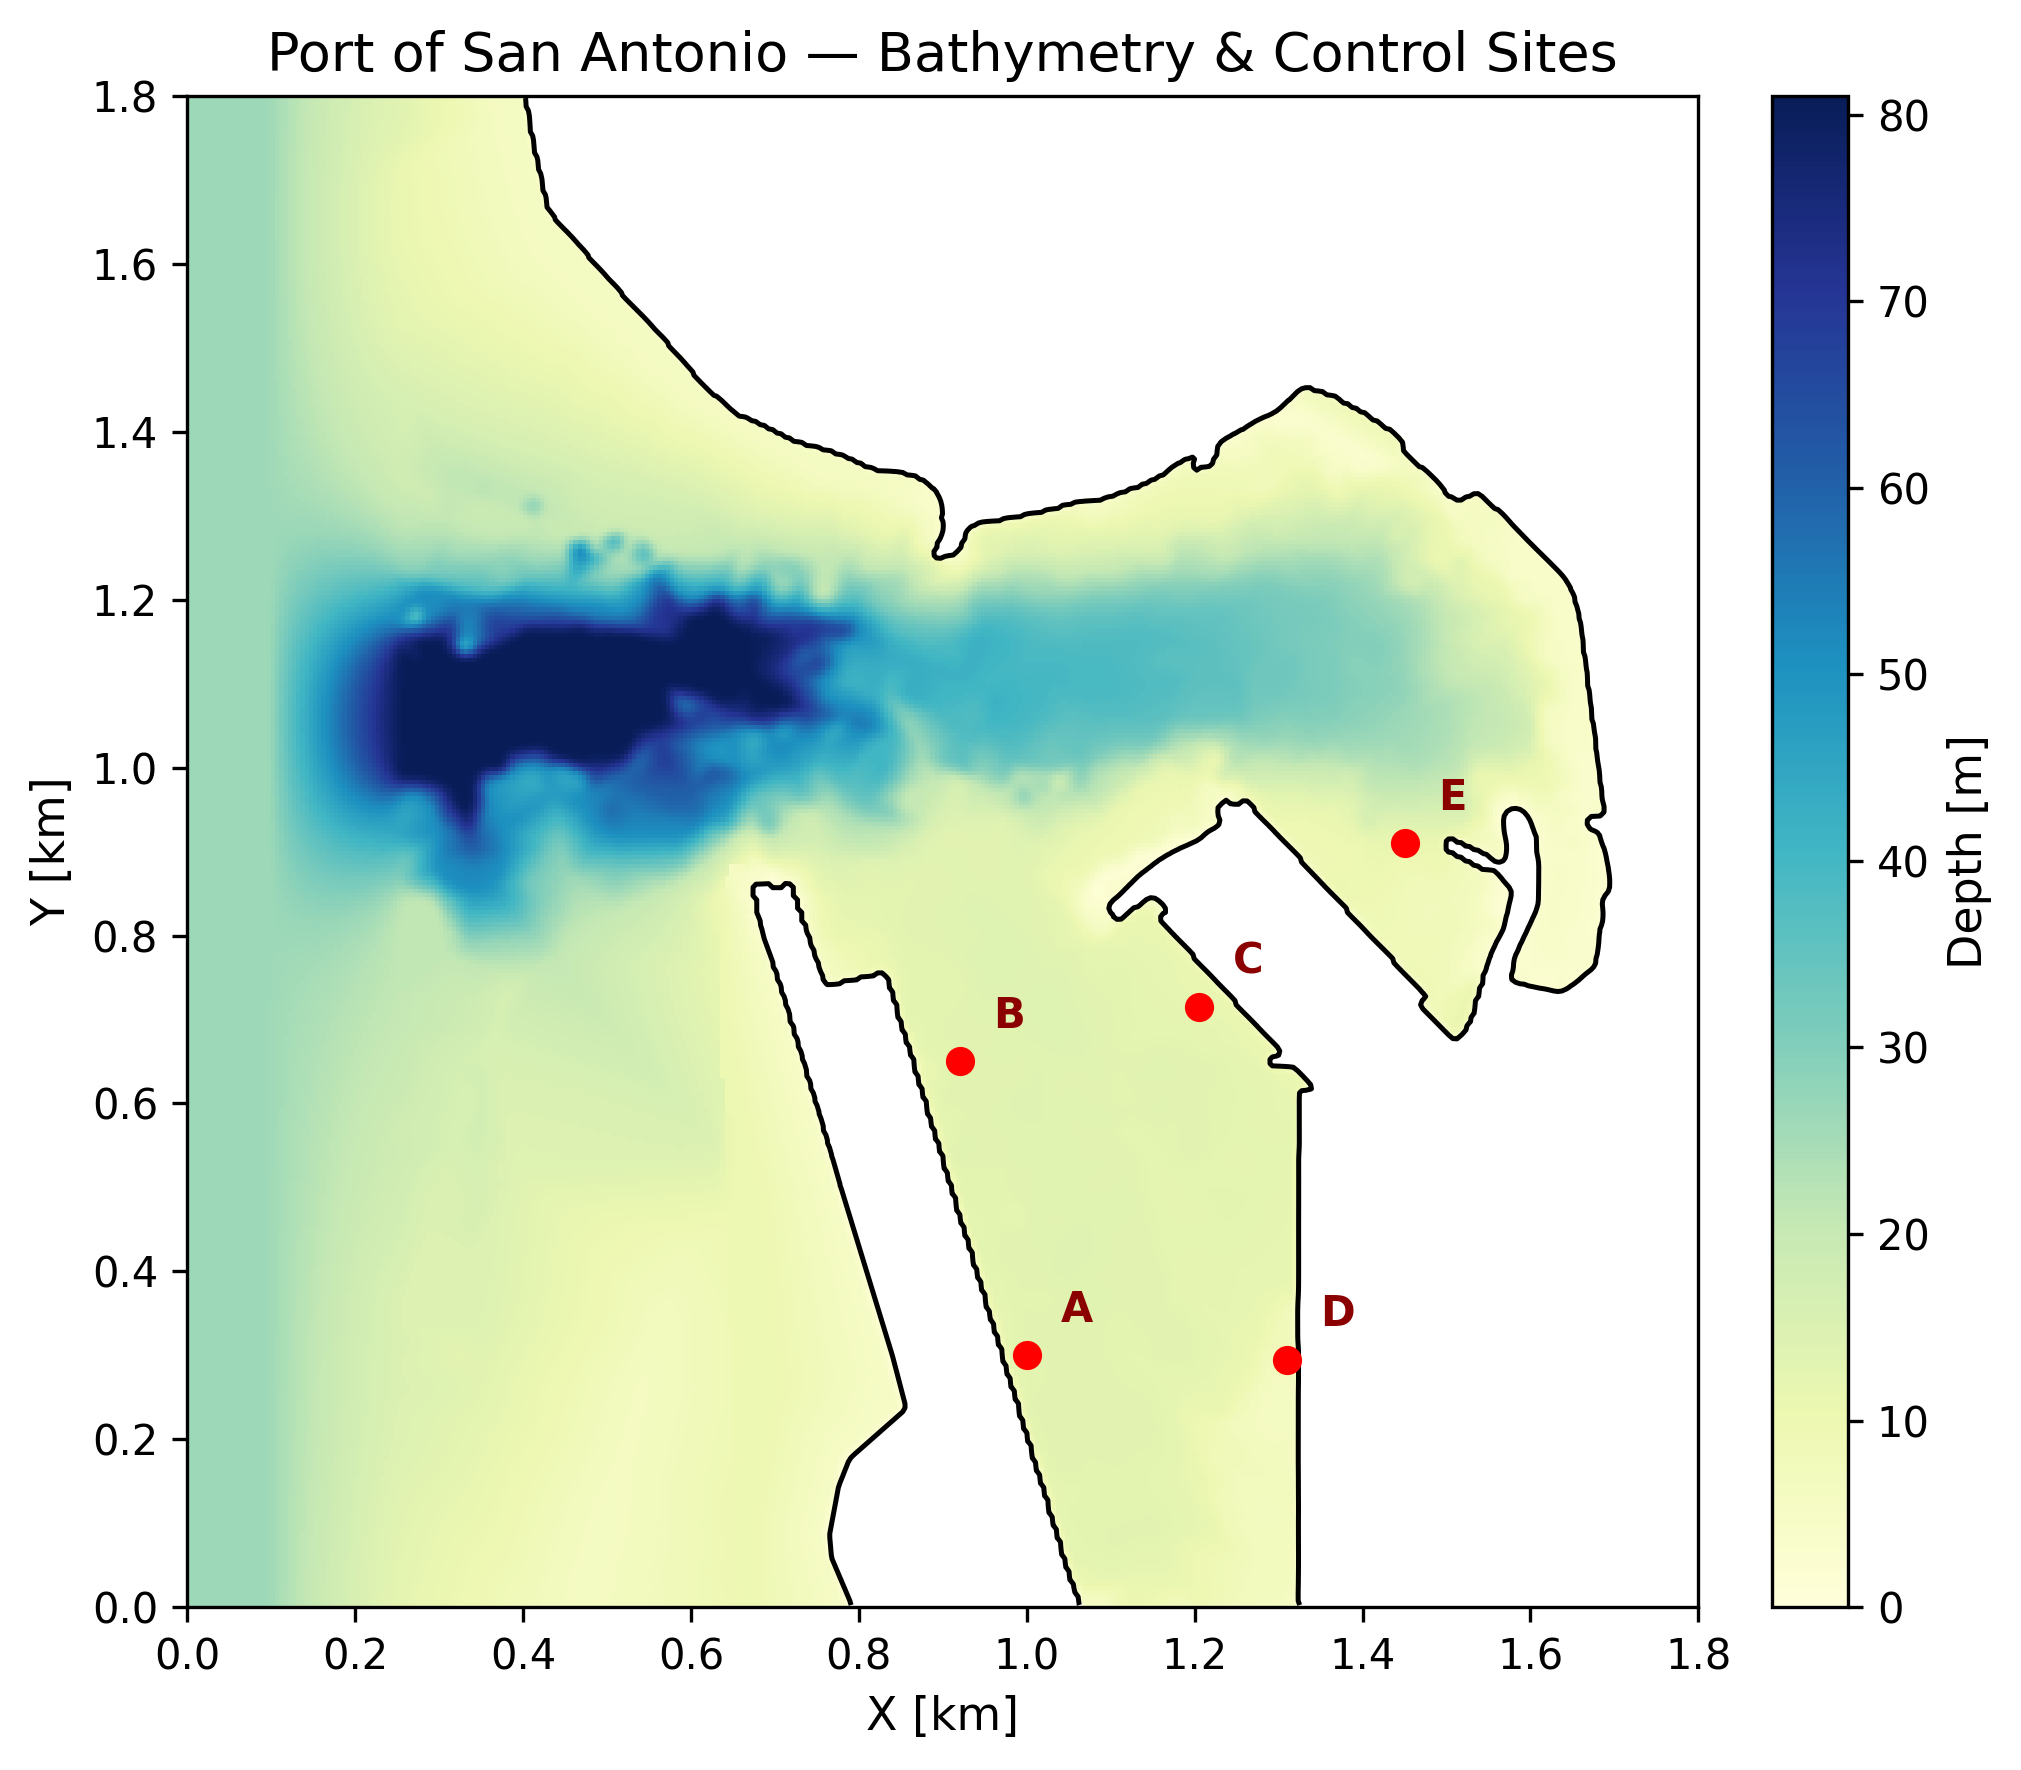

In [3]:
bathy = PortBathymetry.from_config(cfg, "bathy_mod3")
sites_crop = {k: cfg.get_crop_site_coords(k) for k in cfg.control_sites.keys()}

fig = plot_bathymetry(
    depth=bathy.depth_crop,
    dx=cfg.grid.dx,
    dy=cfg.grid.dy,
    sites=sites_crop,
    title=f"Port of {cfg.name} — Bathymetry & Control Sites",
)
plt.show()

### Step 3: Maximum Dissimilarity Algorithm (MDA) Selection
To train the neural operator without propagating all ~100,000 historical hours through FUNWAVE-TVD, the MDA algorithm selects representative sea states that uniformly cover the parameter envelope $(H_{m0}, T_p, \text{Dir})$.

/tmp/ipykernel_1345040/3961188709.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  mda_df = pd.read_csv(mda_path, delim_whitespace=True, skiprows=1, header=None, names=["Hs", "Tp", "Dir", "Dspr"])


Loaded 3000 MDA training states from maxdiss_3000_par.txt


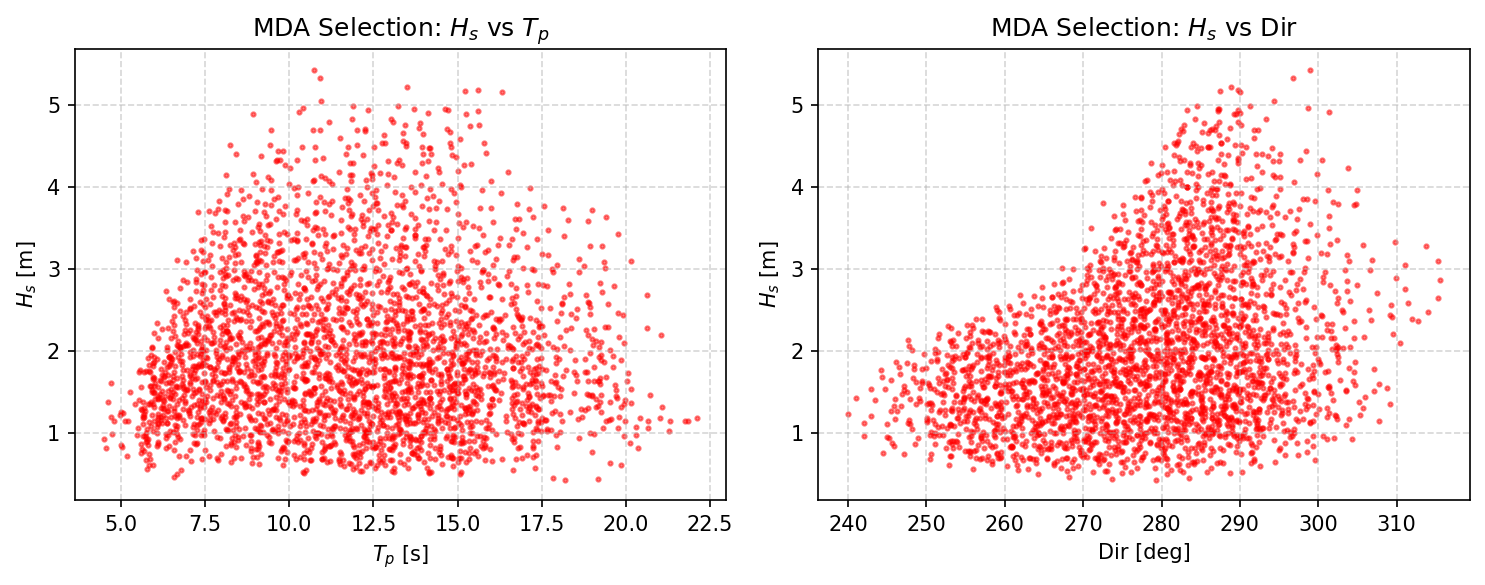

In [4]:
mda_path = cfg.resolve_path("maxdiss_par")
if os.path.exists(mda_path):
    import pandas as pd
    mda_df = pd.read_csv(mda_path, delim_whitespace=True, skiprows=1, header=None, names=["Hs", "Tp", "Dir", "Dspr"])
    print(f"Loaded {len(mda_df)} MDA training states from {os.path.basename(mda_path)}")
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=150)
    axes[0].scatter(mda_df["Tp"], mda_df["Hs"], c="red", s=4, alpha=0.5)
    axes[0].set_title("MDA Selection: $H_s$ vs $T_p$")
    axes[0].set_xlabel("$T_p$ [s]")
    axes[0].set_ylabel("$H_s$ [m]")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    
    axes[1].scatter(mda_df["Dir"], mda_df["Hs"], c="red", s=4, alpha=0.5)
    axes[1].set_title("MDA Selection: $H_s$ vs Dir")
    axes[1].set_xlabel("Dir [deg]")
    axes[1].set_ylabel("$H_s$ [m]")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

### Step 4: Loading the Pre-Trained FNO Surrogate
We instantiate the compact FNO model ($k=45$ modes, channel width $d=32$, padding 4) and load its precalculated weights.

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FNO2d(
    modes1=45,
    modes2=45,
    width=32,
    input_channels=4,
    output_channels=1,
    padding=4
).to(device)

ckpt_dir = cfg.resolve_path("checkpoints_dir")
ckpt_path = os.path.join(ckpt_dir, "fno_maxdiss_3000_v2_best.pth")

if os.path.exists(ckpt_path):
    checkpoint = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = checkpoint["model"] if "model" in checkpoint else checkpoint.get("model_state_dict", checkpoint)
    model.load_state_dict(state)
    model.eval()
    b_val = checkpoint.get("val_relL2", checkpoint.get("best_val_loss", 0.0170))
    print(f"Successfully loaded FNO-v2 checkpoint from: {ckpt_path}")
    print(f"Validation relL2 achieved during training: {b_val:.4f}")
else:
    print(f"Checkpoint not found at: {ckpt_path}")

Successfully loaded FNO-v2 checkpoint from: /home/model2/luis/Doctorado/investigaciones/paper01_fno_2d_hm0/Etapa1/ii_redes_fno_steady/modelos_maxdiss/fno_maxdiss_3000_v2_best.pth
Validation relL2 achieved during training: 0.0170


### Step 5: Real-Time Inference on a Sea State
Let's predict the 2D wave agitation field for an incident sea state: $H_{m0} = 2.80\text{ m}, T_p = 14.5\text{ s}, \text{Dir} = 280^\circ$.

Inference completed in 470.43 ms on cpu


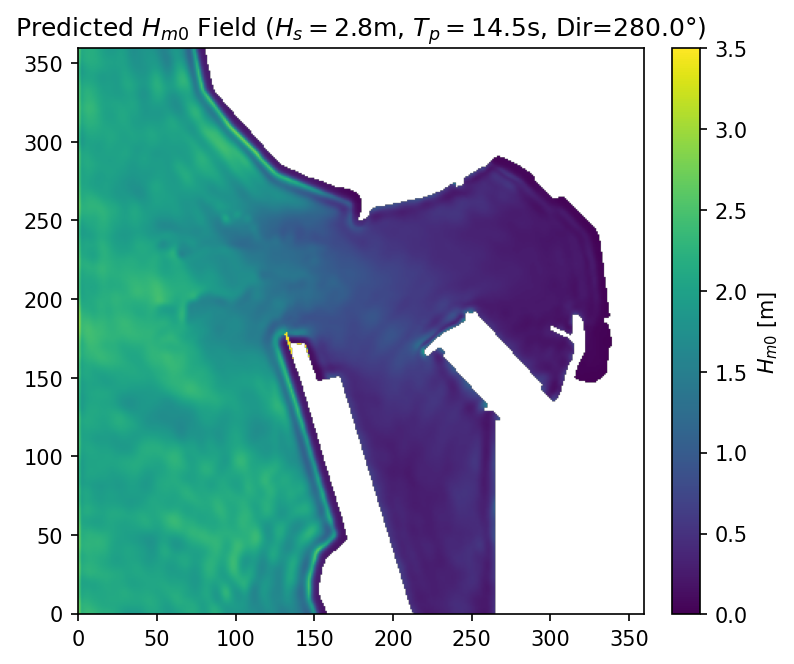

In [6]:
# Load normalization statistics for N=3000
norm_path = os.path.join(cfg.resolve_path("prep_dir"), "norm_stats_maxdiss_3000.npz")
norm_stats = np.load(norm_path)
xnorm = CustomNormalizer(norm_stats["mean_in"], norm_stats["std_in"])

# Construct input tensor [Hmo, FreqPeak, ThetaPeak, Depth]
hs_val = 2.80
tp_val = 14.5
dir_val = 280.0
fp_val = 1.0 / tp_val
theta_val = cfg.boundary.nautical_to_cartesian_offset - dir_val  # 270 - 280 = -10 deg

X_sample = np.empty((1, 360, 360, 4), dtype=np.float32)
X_sample[0, ..., 0] = hs_val
X_sample[0, ..., 1] = fp_val
X_sample[0, ..., 2] = theta_val
X_sample[0, ..., 3] = bathy.depth_crop

# Normalize and predict
X_tensor = xnorm.encode(torch.from_numpy(X_sample)).to(device)
with torch.no_grad():
    import time
    t0 = time.time()
    pred_tensor = model(X_tensor)
    inf_time_ms = (time.time() - t0) * 1000.0

pred_field = pred_tensor[0, ..., 0].cpu().numpy()
print(f"Inference completed in {inf_time_ms:.2f} ms on {device}")

# Mask dry land cells
pred_masked = np.ma.masked_where(bathy.water_mask_crop <= 0, pred_field)

fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
im = ax.imshow(pred_masked, origin="lower", cmap="viridis", vmin=0, vmax=3.5)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("$H_{m0}$ [m]")
ax.set_title(f"Predicted $H_{{m0}}$ Field ($H_s={hs_val}$m, $T_p={tp_val}$s, Dir={dir_val}°)")
plt.show()

### Step 6: Operational Envelope Screening (OOR Safeguard)
A central conclusion of the paper is that **neural surrogates interpolate; they do not extrapolate**.  
We test two incoming sea states with `check_training_envelope`:
- State 1: Operational calm/winter state within training domain.
- State 2: Extreme synthetic storm ($H_s = 6.0\text{ m}, \text{Dir} = 320^\circ$).

In [7]:
tr_pts = mda_df[["Hs", "Tp", "Dir"]].to_numpy()

test_states = np.array([
    [2.5, 14.0, 275.0],  # State 1: In-envelope
    [6.0, 20.0, 320.0],  # State 2: Out of range (Hs > 5.43 m, Dir > 315.6 deg)
])

for i, st_i in enumerate(test_states):
    res = check_training_envelope(st_i, tr_pts)
    print(f"\nEvaluating State {i+1}: Hs={st_i[0]}m, Tp={st_i[1]}s, Dir={st_i[2]}°")
    print(f"  -> Envelope Status: {res['status']}")
    if res['status'] != 'SAFE_INTERPOLATION':
        for feat, viol in res['marginal_violations'].items():
            if viol:
                b_min, b_max = res['bounds'][feat]
                print(f"     [!] ALERT: Feature '{feat}' exceeds bounds [{b_min:.2f}, {b_max:.2f}]")


Evaluating State 1: Hs=2.5m, Tp=14.0s, Dir=275.0°
  -> Envelope Status: SAFE_INTERPOLATION

Evaluating State 2: Hs=6.0m, Tp=20.0s, Dir=320.0°
  -> Envelope Status: EXTRAPOLATION_WARNING
     [!] ALERT: Feature 'Hs' exceeds bounds [0.43, 5.43]
     [!] ALERT: Feature 'Dir' exceeds bounds [240.02, 315.57]


### Step 7: Exporting Results to ParaView (VTK)
We export the predicted 2D field and bathymetry to an ASCII Structured Points `.vtk` file for 3D visualization.

In [8]:
vtk_path = os.path.join(nb_dir, "predicted_wave_field.vtk")
export_field_to_vtk(
    filename=vtk_path,
    fields={
        "Depth": bathy.depth_crop,
        "Predicted_Hm0": pred_field,
        "Water_Mask": bathy.water_mask_crop,
    },
    dx=cfg.grid.dx,
    dy=cfg.grid.dy,
    origin=(cfg.grid.crop.c0 * cfg.grid.dx, cfg.grid.crop.r0 * cfg.grid.dy, 0.0),
    title="Predicted Port Wave Field",
)
print(f"Exported VTK file: {vtk_path} ({os.path.getsize(vtk_path) / 1024:.1f} KB)")

Exported VTK file: /home/model2/luis/Doctorado/investigaciones/paper01_fno_2d_hm0/port_wave_surrogate/notebooks/predicted_wave_field.vtk (2767.3 KB)


---
## Summary & Implementing in Other Ports

To deploy this pipeline in another port domain (such as Valparaíso, Arica, San Vicente, or Iquique):
1. Copy `configs/new_port_template.yaml` and specify the port's bathymetry, grid size, and control berths.
2. Extract offshore boundary wave series from your regional SWAN / WW3 model using `portsurrogate.HindcastData`.
3. Select representative scenarios using `portsurrogate.mda.run_mda(n_centers=2000)`.
4. Run FUNWAVE-GPU with the cascaded CFL runner (`portsurrogate.FUNWAVEBatchRunner`).
5. Train the compact FNO model with `portsurrogate.training.train_fno`.
6. Deploy in real time with automated convex hull screening!